# 2 · Corner detection

`calib.detect.find_corners` finds the 54 inner corners with sub-pixel accuracy:

1. search the board on a **downscaled copy** (≤ 1600 px), with the robust `findChessboardCornersSB` detector and the classic detector as fallback;
2. map the corners back to full resolution;
3. refine them with `cornerSubPix` on the **full-resolution** image.

The downscaled image is only used to *find* the board quickly; its corners are only accurate to one small pixel, i.e. `1/scale` full-resolution pixels. The precision comes from refining at full resolution.
I validated the detector on the synthetic test bench, where the true corner positions are known.

> The webcam sections need captures in `data/webcam/` (mine are not published because they show my face). The saved outputs show my results; every synthetic section runs as is.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from testbench import gt

PATTERN = (9, 6)                              # inner corners of the checkerboard
WEBCAM = ROOT / "data" / "webcam"             # my captures (not published: they show my face)
FIG = ROOT / "docs" / "images"                # figures used in the README
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

In [2]:
import time
from calib.detect import find_corners, edge_sharpness, fix_orientation

def corner_error(c, c_true):
    """Median distance (px) to the truth, trying both corner orders."""
    d1 = np.linalg.norm(c - c_true, axis=-1).ravel()
    d2 = np.linalg.norm(c[::-1] - c_true, axis=-1).ravel()
    return float(min(np.median(d1), np.median(d2)))

rows = []
for f in sorted(gt.data_dir("full").glob("*.jpg")):
    gray = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
    t0 = time.perf_counter()
    c = find_corners(gray, PATTERN)
    dt = time.perf_counter() - t0
    rows.append({"image": f.name, "found": c is not None, "time (s)": dt,
                 "median error (px)": corner_error(c, gt.corners(f"full/{f.name}")) if c is not None else np.nan,
                 "note": gt._note(f"full/{f.name}")})
det = pd.DataFrame(rows)
print(f"median corner error over all found boards: {det['median error (px)'].median():.3f} px, "
      f"mean time {det['time (s)'].mean():.2f} s per 2400x1800 image")
det

median corner error over all found boards: 0.060 px, mean time 0.20 s per 2400x1800 image


,image,found,time (s),median error (px),note
0,img_00.jpg,True,0.151,0.068,good
1,img_01.jpg,True,0.129,0.061,good
2,img_02.jpg,True,0.110,0.073,good
3,img_03.jpg,True,0.117,0.040,good
4,img_04.jpg,True,0.106,0.038,good
5,img_05.jpg,True,0.117,0.073,good
6,img_06.jpg,True,0.108,0.037,good
7,img_07.jpg,True,0.107,0.080,motion blur (17 px horizontal)
8,img_08.jpg,False,1.987,NaN,board partly outside the image
9,img_09.jpg,True,0.109,0.059,good


**Result:** median corner error **0.06 px** (all images below 0.1 px) on 2400×1800 images, ≈ 0.11 s per image (≈ 2 s when no complete board is present, because both detectors run). The board that is partly outside the image (`img_08`) is correctly rejected (`None`) rather than returned incomplete.

### Zoom on one corner

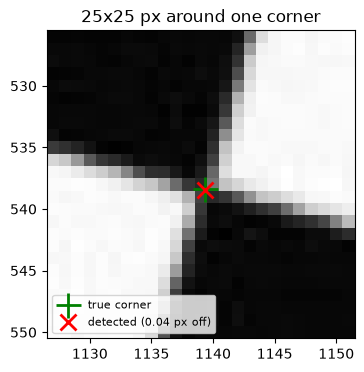

In [3]:
name = "full/img_03.jpg"
gray = cv2.imread(str(gt.data_dir("full") / "img_03.jpg"), cv2.IMREAD_GRAYSCALE)
c = fix_orientation(gray, find_corners(gray, PATTERN), PATTERN).reshape(-1, 2)
t = gt.corners(name).reshape(-1, 2)

x, y = t[22].astype(int)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(gray[y - 12:y + 13, x - 12:x + 13], cmap="gray", extent=(x - 12.5, x + 12.5, y + 12.5, y - 12.5))
ax.plot(*t[22], "g+", ms=18, mew=2, label="true corner")
ax.plot(*c[22], "rx", ms=12, mew=2, label=f"detected ({np.linalg.norm(c[22] - t[22]):.2f} px off)")
ax.legend(loc="lower left", fontsize=8); ax.set_title("25x25 px around one corner")
plt.show()

## Sharpness: catching motion blur in one direction

`edge_sharpness` samples intensity profiles across the square edges and measures the 10–90 % rise width (px), separately **across vertical and horizontal edges**, and reports the worse one.
OpenCV's `estimateChessboardSharpness` gives a comparable number per direction (`vertical=False/True`).

In [4]:
rows = []
for f in sorted(gt.data_dir("full").glob("*.jpg")):
    gray = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
    c = find_corners(gray, PATTERN)
    if c is None:
        continue
    (h, *_), _ = cv2.estimateChessboardSharpness(gray, PATTERN, c, vertical=False)
    (v, *_), _ = cv2.estimateChessboardSharpness(gray, PATTERN, c, vertical=True)
    rows.append({"image": f.name, "opencv horizontal": h, "opencv vertical": v,
                 "edge width (px)": edge_sharpness(gray, PATTERN, c), "note": gt._note(f"full/{f.name}")})
pd.DataFrame(rows).sort_values("edge width (px)", ascending=False).head(5)

,image,opencv horizontal,opencv vertical,edge width (px),note
7,img_07.jpg,2.315,13.678,13.772,motion blur (17 px horizontal)
9,img_10.jpg,2.251,2.271,2.329,focus changed: different K and distortion
2,img_02.jpg,2.351,2.255,2.257,good
18,img_19.jpg,2.332,2.337,2.247,good
12,img_13.jpg,2.421,2.424,2.223,good


`img_07` stands out (≈ 13.8 px vs ≈ 2 px): it has **horizontal motion blur**, which widens the vertical edges only. A single averaged sharpness value would dilute it; measuring both directions and keeping the worse one catches it.

## My webcam frames

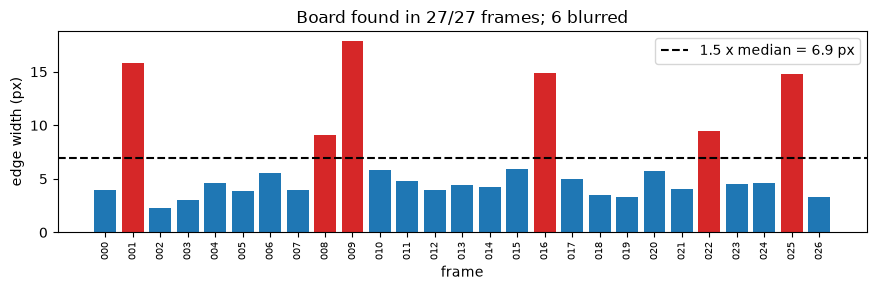

In [5]:
rows = []
for f in sorted((WEBCAM / "calib_1920x1080").glob("*.png")):
    gray = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
    c = find_corners(gray, PATTERN)
    rows.append({"frame": f.stem[-3:], "found": c is not None,
                 "edge width (px)": edge_sharpness(gray, PATTERN, c) if c is not None else np.nan})
cam = pd.DataFrame(rows)
thr = 1.5 * cam["edge width (px)"].median()
cam["sharp"] = cam["edge width (px)"] <= thr

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(cam["frame"], cam["edge width (px)"], color=np.where(cam["sharp"], "tab:blue", "tab:red"))
ax.axhline(thr, color="k", ls="--", label=f"1.5 x median = {thr:.1f} px")
ax.set_xlabel("frame"); ax.set_ylabel("edge width (px)"); ax.legend()
ax.set_title(f"Board found in {cam['found'].sum()}/{len(cam)} frames; {(~cam['sharp']).sum()} blurred")
plt.xticks(rotation=90, fontsize=7); fig.tight_layout(); fig.savefig(FIG / "sharpness_webcam.png", dpi=120); plt.show()

The board was found in all 27 frames. Six frames (red) have edges 9–18 px wide versus a typical 3–6 px: the phone moved during the exposure. Notebook 3 checks whether they hurt the calibration.